# 4. Two-dimensional steady conduction

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 2 and 3

The district-heating pipe of Chapter 1 hung in the air. Most district-heating pipes are
buried, and then the heat leaving the pipe spreads through the soil in two dimensions
before it reaches the ground surface. This chapter answers the questions a network
designer asks. How much heat does a buried pre-insulated pipe lose? How much does the
soil matter, compared with the insulation? And when the supply and return pipes share a
trench, how much does each warm the other?

Two exact methods do the work: separation of variables, and line sources with their
images. A finite-difference solver that handles circular pipes checks both, and shows
how accurate the simple line-source model of two pipes is.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np

try:
    from engtransport import reference
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    from engtransport import reference
from engtransport.plotting import panel_label, use_style

use_style()

## 4.1 Laplace's equation and the shape factor

In a steady state with no heat generated and a constant conductivity, the energy balance
on a small element, with Fourier's law for the flux, gives Laplace's equation:

$$
\frac{\partial^2 T}{\partial x^2} + \frac{\partial^2 T}{\partial y^2} = 0 .
\tag{4.1}
$$

Two of its properties do most of the work. Its solution is unique once the temperature
(or the flux) is given on every boundary. And it is linear, so solutions can be added:
the temperature for two sources is the sum of the temperatures for each.

When heat flows between two surfaces, each at a uniform temperature, the heat flow is
proportional to the temperature difference and to $k$. What remains depends only on the
geometry and is called the *shape factor* $S$. For long objects we use the shape factor
per unit length $S'$, so that

$$
q' = S'\,k\,(T_1 - T_2), \qquad R' = \frac{1}{S'k} .
\tag{4.2}
$$

For a cylindrical shell, $S' = 2\pi/\ln(r_2/r_1)$ (Chapter 2). The rest of the chapter
finds $S'$ for shapes where the heat flows in two dimensions.

## 4.2 Separation of variables: a bar with one hot face

A long steel bar of square cross-section, $W = 100$ mm on a side, rests on a hot plate at
$T_1 = 100$ °C; its other three faces are water-cooled at $T_0 = 20$ °C. Put $x$ across the
bar and $y$ upwards from the hot face, and let $\theta = (T - T_0)/(T_1 - T_0)$. Trying
$\theta = X(x)Y(y)$ in Eq. (4.1) separates it into $X''/X = -Y''/Y = -\lambda^2$. The
conditions $\theta = 0$ at $x = 0$ and $x = W$ select $X = \sin(n\pi x/W)$, and $\theta = 0$
on the top face $y = H$ selects $Y = \sinh(n\pi(H - y)/W)$. The coefficients that make
$\theta = 1$ on the hot face are the Fourier sine coefficients of a constant:

$$
\theta = \sum_{n\ {\rm odd}} \frac{4}{n\pi}\,\sin\frac{n\pi x}{W}\;
\frac{\sinh\left(n\pi (H - y)/W\right)}{\sinh\left(n\pi H/W\right)} .
\tag{4.3}
$$

Each term decays away from the hot face over a distance $W/n\pi$, so far from it only the
first term remains:

$$
\theta \approx \frac{4}{\pi}\,\sin\frac{\pi x}{W}\; e^{-\pi y/W}
\qquad (y \gtrsim W/2,\ H \gg W) .
\tag{4.4}
$$

This is a rule worth remembering: a disturbance imposed on one edge of a strip of width
$W$ fades by a factor $e^{-\pi} \approx 1/23$ over a distance $W$. It is why the corner of a
wall, or the root of the balcony slab of Chapter 3, disturbs the temperature only within
about one wall thickness of it.

Superposition gives one result without any series. Four problems, each with a different
face at $T_1$ and the others at $T_0$, add up to the whole bar at $T_1$. By symmetry they
contribute equally at the centre, so the centre of the bar is at $T_0 + (T_1 - T_0)/4 =
40$ °C:

In [2]:
def bar_theta(x, y, W=1.0, H=1.0, n_terms=401):
    """Eq. (4.3): one hot face (y = 0), the other three at theta = 0."""
    x, y = np.broadcast_arrays(np.asarray(x, float), np.asarray(y, float))
    n = np.arange(1, n_terms + 1, 2).reshape((-1,) + (1,) * x.ndim)
    # sinh(n pi (H - y)/W) / sinh(n pi H/W), written to avoid overflow
    ratio = np.exp(-n * np.pi * y / W) * (1 - np.exp(-2 * n * np.pi * (H - y) / W)) / (1 - np.exp(-2 * n * np.pi * H / W))
    return np.sum(4 / (n * np.pi) * np.sin(n * np.pi * x / W) * ratio, axis=0)


W_bar, T0, T1 = 0.100, 20.0, 100.0
print(f"centre of the bar: series {T0 + (T1 - T0) * float(bar_theta(0.5, 0.5)):.6f} C, superposition 40 C")
for n_terms in (1, 3, 11, 101):
    print(f"  with {(n_terms + 1) // 2:2d} terms: {T0 + (T1 - T0) * float(bar_theta(0.5, 0.5, n_terms=n_terms)):.6f} C")
y_1K = W_bar / math.pi * math.log(4 / math.pi * (T1 - T0) / 1.0)
print(f"on the centre line of a long bar, within 1 K of the cold faces beyond y = {1e3 * y_1K:.0f} mm")

centre of the bar: series 40.000000 C, superposition 40 C
  with  1 terms: 40.297313 C
  with  2 terms: 39.992328 C
  with  6 terms: 40.000000 C
  with 51 terms: 40.000000 C
on the centre line of a long bar, within 1 K of the cold faces beyond y = 147 mm


The series converges quickly in the interior: the first term alone gives 40.3 °C, and two
terms 39.99 °C. Near the corners where the hot face meets the cold ones it converges
slowly, because there the temperature jumps. Along the centre line of a long bar the
temperature is within 1 K of the cold faces beyond 147 mm, about 1.5 widths, from the hot
face.

## 4.3 A line source and its image: a buried pipe

A long thin pipe that gives out $q'$ per metre in an infinite solid is a *line source*.
Around it the heat flows radially, and integrating $q' = -2\pi r k\,dT/dr$ gives

$$
T = -\frac{q'}{2\pi k}\,\ln r + C .
\tag{4.5}
$$

A buried pipe is not in an infinite solid: the ground surface, $y = 0$, is held at $T_s$.
Place a *sink* of strength $-q'$ at the mirror image of the source, a distance $a$ above the
surface. The source and the sink cancel on the surface, which is therefore at $T_s$, and
the temperature below it is

$$
T - T_s = \frac{q'}{4\pi k}\,\ln\frac{x^2 + (y + a)^2}{x^2 + (y - a)^2} ,
\tag{4.6}
$$

with $y$ the depth. The isotherms of Eq. (4.6) are circles whose centres lie below the
source (Figure 4.1b). One of them is the surface of a pipe of radius $r$ whose centre is
at depth $z$, provided $a = \sqrt{z^2 - r^2}$. Evaluating Eq. (4.6) on that circle gives
the shape factor of a buried cylinder:

$$
S' = \frac{2\pi}{\cosh^{-1}(z/r)} \approx \frac{2\pi}{\ln(2z/r)}
\quad (z \gg r) .
\tag{4.7}
$$

A pre-insulated district-heating pipe is a steel pipe (the 114.3 mm pipe of Chapter 1)
inside polyurethane foam, $k = 0.027$ W/(m K), with a polyethylene casing 225 mm across.
It is buried with its centre 1.0 m below the surface in moist soil, $k_s = 1.5$ W/(m K).
Take the ground surface at 0 °C and the water at 110 °C. The insulation and the soil are
in series:

$$
q' = \frac{T_w - T_s}{R'_{\rm ins} + R'_{\rm soil}}, \qquad
R'_{\rm ins} = \frac{\ln(r_2/r_1)}{2\pi k_{\rm ins}}, \qquad
R'_{\rm soil} = \frac{\cosh^{-1}(z/r_2)}{2\pi k_s} .
\tag{4.8}
$$

In [3]:
r1, r2, k_ins = 0.05715, 0.1125, 0.027
z, k_s, T_s = 1.0, 1.5, 0.0
T_sup, T_ret = 110.0, 50.0
R_ins = math.log(r2 / r1) / (2 * math.pi * k_ins)
R_soil = math.acosh(z / r2) / (2 * math.pi * k_s)
q_sup_alone = (T_sup - T_s) / (R_ins + R_soil)
q_ret_alone = (T_ret - T_s) / (R_ins + R_soil)
print(f"R'_ins = {R_ins:.3f} m K/W, R'_soil = {R_soil:.3f} m K/W (soil {R_soil / (R_ins + R_soil):.1%} of the total)")
print(f"supply pipe alone: {q_sup_alone:.1f} W/m; return pipe alone: {q_ret_alone:.1f} W/m")
print(f"cosh^-1(z/r2) = {math.acosh(z / r2):.4f}, ln(2z/r2) = {math.log(2 * z / r2):.4f}")
q_bare = 2 * math.pi * k_s * (T_sup - T_s) / math.acosh(z / r1)
print(f"bare steel pipe in the same soil: {q_bare:.0f} W/m")
for kk in (0.4, 2.5):
    print(f"k_s = {kk}: pre-insulated {(T_sup - T_s) / (R_ins + math.acosh(z / r2) / (2 * math.pi * kk)):.1f} W/m,"
          f" bare {2 * math.pi * kk * (T_sup - T_s) / math.acosh(z / r1):.0f} W/m")

R'_ins = 3.992 m K/W, R'_soil = 0.305 m K/W (soil 7.1% of the total)
supply pipe alone: 25.6 W/m; return pipe alone: 11.6 W/m
cosh^-1(z/r2) = 2.8748, ln(2z/r2) = 2.8779
bare steel pipe in the same soil: 292 W/m
k_s = 0.4: pre-insulated 21.4 W/m, bare 78 W/m
k_s = 2.5: pre-insulated 26.3 W/m, bare 486 W/m


The buried supply pipe loses 25.6 W/m, against 63.7 W/m for the pipe of Chapter 1 in
−35 °C air with 50 mm of mineral wool. The soil carries only 7 % of the resistance: the
insulation does the work, and the soil matters only where the insulation has failed. A
bare steel pipe in the same soil would lose 292 W/m. For a pipe 1 m deep the logarithmic
approximation in Eq. (4.7) is good to 0.1 %.

## 4.4 Supply and return in one trench

The supply and return pipes are laid side by side, a distance $s$ apart between centres.
Each pipe is a line source with its image, and by superposition the temperature at the
casing of pipe $i$ is the sum of its own contribution and that of pipe $j$ and its image.
Treating each casing as an isotherm gives two linear equations:

$$
T_i - T_s = \left(R'_{\rm ins} + R'_{\rm soil}\right) q'_i + R'_m\, q'_j, \qquad
R'_m = \frac{1}{2\pi k_s}\,\ln\frac{\sqrt{s^2 + 4z^2}}{s} .
\tag{4.9}
$$

$R'_m$ is the *mutual resistance*: the temperature rise at one pipe per watt per metre given
out by the other.

In [4]:
def two_pipes(s, T_a=T_sup, T_b=T_ret):
    R_m = math.log(math.sqrt(s**2 + 4 * z**2) / s) / (2 * math.pi * k_s)
    A = np.array([[R_ins + R_soil, R_m], [R_m, R_ins + R_soil]])
    q = np.linalg.solve(A, [T_a - T_s, T_b - T_s])
    T_casing = T_s + np.array([[R_soil, R_m], [R_m, R_soil]]) @ q
    return q, R_m, T_casing


s_trench = 0.40
q_pair, R_m, T_casing = two_pipes(s_trench)
print(f"s = {s_trench} m: R'_m = {R_m:.3f} m K/W")
print(f"supply {q_pair[0]:.2f} W/m ({q_pair[0] / q_sup_alone - 1:+.1%}), return {q_pair[1]:.2f} W/m"
      f" ({q_pair[1] / q_ret_alone - 1:+.1%}); together {q_pair.sum():.1f} W/m"
      f" instead of {q_sup_alone + q_ret_alone:.1f} W/m")
print(f"casing temperatures {T_casing[0]:.1f} C and {T_casing[1]:.1f} C")

s = 0.4 m: R'_m = 0.173 m K/W
supply 25.17 W/m (-1.7%), return 10.62 W/m (-8.7%); together 35.8 W/m instead of 37.2 W/m
casing temperatures 9.5 C and 7.6 C


With 0.4 m between centres, the return pipe loses 9 % less heat than it would alone,
because it sits in soil warmed by the supply pipe; the supply pipe loses 2 % less. The
pair loses 35.8 W per metre of trench, 4 % less than two separate pipes. The effect is
small because the casings are only 8–10 °C above the ground surface: almost all of the
temperature difference is taken up by the foam.

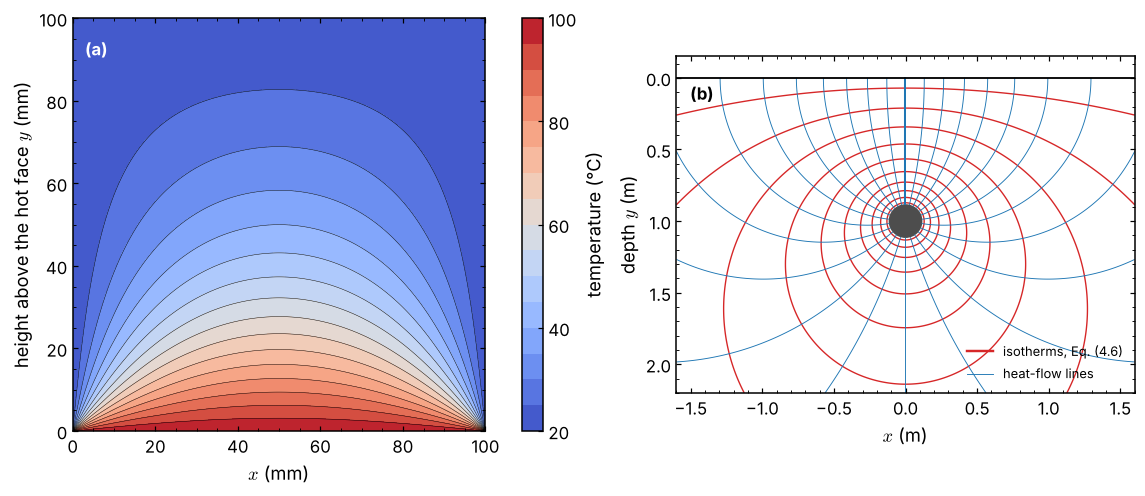

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.4))
xb = np.linspace(0, 1, 201)
yb = np.linspace(0, 1, 201)
XB, YB = np.meshgrid(xb, yb)
TB = T0 + (T1 - T0) * bar_theta(XB, YB)
cs = ax1.contourf(XB * 1e3 * W_bar, YB * 1e3 * W_bar, TB, levels=np.arange(20, 101, 5), cmap="coolwarm")
ax1.contour(XB * 1e3 * W_bar, YB * 1e3 * W_bar, TB, levels=np.arange(25, 100, 5), colors="k", linewidths=0.3)
fig.colorbar(cs, ax=ax1, label="temperature (°C)", ticks=[20, 40, 60, 80, 100])
ax1.set_xlabel("$x$ (mm)")
ax1.set_ylabel("height above the hot face $y$ (mm)")
ax1.set_aspect("equal")
panel_label(ax1, "(a)", color="w")

a_img = math.sqrt(z**2 - r2**2)
xg = np.linspace(-1.6, 1.6, 401)
yg = np.linspace(0, 2.2, 301)
XG, YG = np.meshgrid(xg, yg)
theta_g = np.log((XG**2 + (YG + a_img) ** 2) / (XG**2 + (YG - a_img) ** 2)) / (2 * math.acosh(z / r2))
psi = np.angle((XG + 1j * (YG - a_img)) / (XG + 1j * (YG + a_img)))     # heat-flow lines
inside = XG**2 + (YG - z) ** 2 < r2**2
theta_g[inside] = np.nan
psi[inside] = np.nan
ax2.contour(XG, YG, theta_g, levels=np.linspace(0.05, 0.95, 10), colors="C3", linewidths=0.9)
ax2.contour(XG, YG, psi, levels=np.linspace(-math.pi, math.pi, 25)[1:-1], colors="C0", linewidths=0.6,
            linestyles="-")
ax2.add_patch(plt.Circle((0, z), r2, color="0.3"))
ax2.axhline(0, color="k", lw=1.2)
ax2.set_xlim(-1.6, 1.6)
ax2.set_ylim(2.2, -0.15)
ax2.set_aspect("equal")
ax2.set_xlabel("$x$ (m)")
ax2.set_ylabel("depth $y$ (m)")
ax2.plot([], [], "C3", label="isotherms, Eq. (4.6)")
ax2.plot([], [], "C0", lw=0.6, label="heat-flow lines")
ax2.legend(loc="lower right", fontsize=8.5)
panel_label(ax2, "(b)", y=0.92)
plt.show()

**Figure 4.1.** (a) Temperature in the bar of Section 4.2, from the series (4.3), with the
hot face at the bottom. (b) A buried pipe (grey) seen as a line source below the ground
surface: the isotherms of Eq. (4.6) (red, from 5 % to 95 % of the excess temperature of the
casing) are circles whose centres lie below the source, and the heat leaves along circular
arcs (blue) that run from the pipe to the surface.

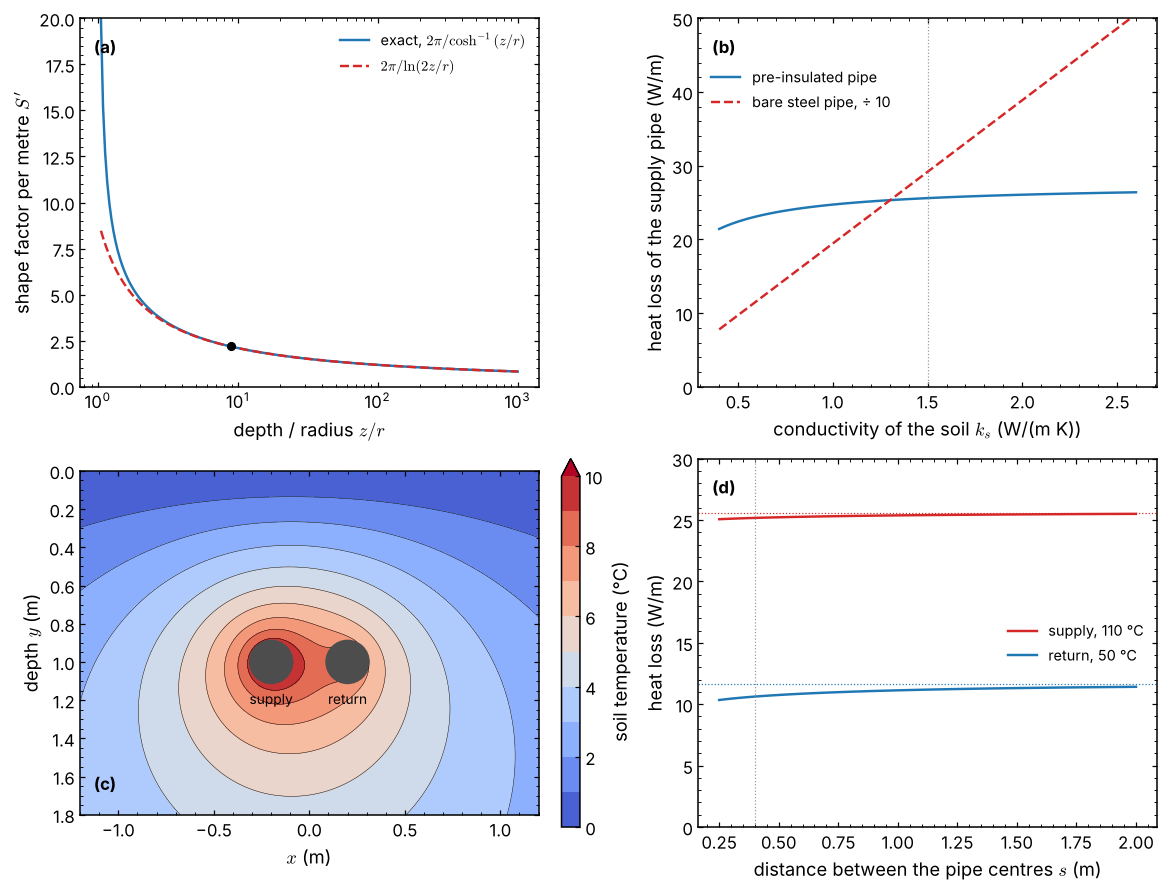

In [6]:
spacings = np.linspace(0.25, 2.0, 60)
pairs = np.array([two_pipes(s)[0] for s in spacings])
ks_range = np.linspace(0.4, 2.6, 60)

fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.0))
ax = axes[0, 0]
zr = np.logspace(np.log10(1.05), 3, 200)
ax.semilogx(zr, 2 * np.pi / np.arccosh(zr), "C0", label=r"exact, $2\pi/\cosh^{-1}(z/r)$")
ax.semilogx(zr, 2 * np.pi / np.log(2 * zr), "C3--", label=r"$2\pi/\ln(2z/r)$")
ax.plot([z / r2], [2 * math.pi / math.acosh(z / r2)], "ko", ms=5)
ax.set_xlabel("depth / radius $z/r$")
ax.set_ylabel("shape factor per metre $S'$")
ax.set_ylim(0, 20)
ax.legend(loc="upper right")
panel_label(ax, "(a)")

ax = axes[0, 1]
ax.plot(ks_range, [(T_sup - T_s) / (R_ins + math.acosh(z / r2) / (2 * math.pi * kk)) for kk in ks_range],
        "C0", label="pre-insulated pipe")
ax.plot(ks_range, [2 * math.pi * kk * (T_sup - T_s) / math.acosh(z / r1) / 10 for kk in ks_range], "C3--",
        label="bare steel pipe, ÷ 10")
ax.axvline(k_s, color="0.6", lw=0.8, ls=":")
ax.set_xlabel("conductivity of the soil $k_s$ (W/(m K))")
ax.set_ylabel("heat loss of the supply pipe (W/m)")
ax.set_ylim(0, 50)
ax.legend(loc="upper left", bbox_to_anchor=(0.0, 0.9))
panel_label(ax, "(b)")

ax = axes[1, 0]
xg2 = np.linspace(-1.2, 1.2, 481)
yg2 = np.linspace(0, 1.8, 361)
XG2, YG2 = np.meshgrid(xg2, yg2)
T_field = np.full_like(XG2, T_s)
for xc, q in ((-s_trench / 2, q_pair[0]), (s_trench / 2, q_pair[1])):
    T_field += q / (4 * math.pi * k_s) * np.log(((XG2 - xc) ** 2 + (YG2 + z) ** 2) / ((XG2 - xc) ** 2 + (YG2 - z) ** 2))
for xc in (-s_trench / 2, s_trench / 2):
    T_field[(XG2 - xc) ** 2 + (YG2 - z) ** 2 < r2**2] = np.nan
cs = ax.contourf(XG2, YG2, T_field, levels=np.arange(0, 11, 1), cmap="coolwarm", extend="max")
ax.contour(XG2, YG2, T_field, levels=np.arange(1, 11, 1), colors="k", linewidths=0.3)
for xc, name in ((-s_trench / 2, "supply"), (s_trench / 2, "return")):
    ax.add_patch(plt.Circle((xc, z), r2, color="0.3"))
    ax.text(xc, z + 0.22, name, ha="center", fontsize=9)
ax.set_xlim(-1.2, 1.2)
ax.set_ylim(1.8, 0)
ax.set_aspect("equal")
ax.set_xlabel("$x$ (m)")
ax.set_ylabel("depth $y$ (m)")
fig.colorbar(cs, ax=ax, label="soil temperature (°C)", ticks=[0, 2, 4, 6, 8, 10])
panel_label(ax, "(c)", y=0.12)

ax = axes[1, 1]
ax.plot(spacings, pairs[:, 0], "C3", label="supply, 110 °C")
ax.plot(spacings, pairs[:, 1], "C0", label="return, 50 °C")
ax.axhline(q_sup_alone, color="C3", lw=0.8, ls=":")
ax.axhline(q_ret_alone, color="C0", lw=0.8, ls=":")
ax.axvline(s_trench, color="0.6", lw=0.8, ls=":")
ax.set_xlabel("distance between the pipe centres $s$ (m)")
ax.set_ylabel("heat loss (W/m)")
ax.set_ylim(0, 30)
ax.legend(loc="center right")
panel_label(ax, "(d)")
plt.show()

**Figure 4.2.** (a) Shape factor per metre of a buried cylinder against the ratio of its
depth to its radius, exact and logarithmic, Eq. (4.7); the point is the casing of the
district-heating pipe. (b) Heat loss of the supply pipe against the conductivity of the
soil, for the pre-insulated pipe and for a bare steel pipe (divided by 10); the dotted
line is the moist soil of the text. (c) Soil temperature around supply and return pipes
0.4 m apart, by superposition, Eq. (4.9). (d) Heat losses of the two pipes against their
spacing; the dotted lines are the losses of each pipe alone.

Figure 4.2b shows the practical lesson: from dry sand ($k_s \approx 0.4$ W/(m K)) to wet
clay ($k_s \approx 2.5$ W/(m K)), the loss of the pre-insulated pipe rises from 21.4 to
26.3 W/m, by 23 %, while that of the bare pipe rises in proportion to $k_s$, by a factor of
6.

## 4.5 Checks

`reference.laplace_2d_fd` solves Eq. (4.1) by finite differences on a square grid. Where a
grid line crosses a pipe, it uses the exact distance from the node to the circle (the
Shortley–Weller stencil), so the scheme stays second order although the pipe does not fit
the grid. The heat leaving each pipe is the sum of the fluxes across a square of cell
faces around it. The solver knows nothing about line sources or images.

*Separation of variables.* The bar of Section 4.2, on grids from 11 to 161 nodes a side.

*The single pipe.* First with the exact temperature (4.6) imposed on the edges of a 3 m
square around the pipe: any error is then the solver's own. Then with the far edges held
at $T_s$ or insulated, on squares from 2 to 16 m: the two choices bracket the infinite
soil, and their errors measure how far away a computational boundary must be.

*Two pipes.* For two isothermal casings, the solver gives the exact 2×2 matrix of soil
conductances, which Eq. (4.9) approximates by line sources. Solving the insulation in
series with each matrix shows how much the approximation changes the heat losses.

In [7]:
theta_line = lambda X, Y: np.log((X**2 + (Y + a_img) ** 2) / (X**2 + (Y - a_img) ** 2)) / (2 * math.acosh(z / r2))
S_exact = 2 * math.pi / math.acosh(z / r2)

hs = np.array([0.04, 0.02, 0.01])
err_pipe = []
for h in hs:
    out = reference.laplace_2d_fd(3.0, 3.0, h, circles=[(0.0, z, r2, 1.0)], top=("temperature", 0.0),
                                  left=("insulated",), right=("temperature", lambda y: theta_line(3.0, y)),
                                  bottom=("temperature", lambda x: theta_line(x, 3.0)))
    err_pipe.append(abs(2 * out["Q_circles"][0] / S_exact - 1))     # the domain is half the soil
err_pipe = np.array(err_pipe)

n_bar = np.array([11, 21, 41, 81, 161])
err_bar = []
for n in n_bar:
    out = reference.laplace_2d_fd(1.0, 1.0, 1.0 / (n - 1), top=("temperature", 1.0), bottom=("temperature", 0.0),
                                  left=("temperature", 0.0), right=("temperature", 0.0))
    j, i = (n - 1) // 4, (n - 1) // 4                                 # the point (W/4, W/4)
    err_bar.append(abs(out["T"][j, i] - float(bar_theta(0.25, 0.25))))
err_bar = np.array(err_bar)
order = lambda e, h: np.polyfit(np.log(h), np.log(e), 1)[0]
print(f"bar: error at (W/4, W/4) {err_bar[-1]:.1e} with 161 nodes, order {order(err_bar, 1 / (n_bar - 1)):.2f}")
print(f"single pipe, exact edges: error in S' {err_pipe[-1]:.1e} at h = 10 mm, order {order(err_pipe, hs):.2f}")

sizes = np.array([2.0, 4.0, 8.0, 16.0])
err_fixed, err_insul = [], []
for L in sizes:
    h = 0.04 if L < 16 else 0.05
    for bc, store in ((("temperature", 0.0), err_fixed), (("insulated",), err_insul)):
        out = reference.laplace_2d_fd(L, L, h, circles=[(0.0, z, r2, 1.0)], top=("temperature", 0.0),
                                      left=("insulated",), right=bc, bottom=bc)
        store.append(2 * out["Q_circles"][0] / S_exact - 1)
err_fixed, err_insul = np.array(err_fixed), np.array(err_insul)
for L, ef, ei in zip(sizes, err_fixed, err_insul):
    print(f"soil {L:4.0f} m square: far edges at T_s {ef:+.4f}, insulated {ei:+.4f}, mean {(ef + ei) / 2:+.4f}")

bar: error at (W/4, W/4) 2.5e-06 with 161 nodes, order 3.04
single pipe, exact edges: error in S' 3.0e-06 at h = 10 mm, order 3.65


soil    2 m square: far edges at T_s +0.1878, insulated -0.1264, mean +0.0307
soil    4 m square: far edges at T_s +0.0384, insulated -0.0356, mean +0.0014
soil    8 m square: far edges at T_s +0.0089, insulated -0.0096, mean -0.0003
soil   16 m square: far edges at T_s +0.0018, insulated -0.0028, mean -0.0005


In [8]:
def soil_conductances_fd(s, size=8.0, h=0.02):
    """2x2 soil conductance matrix of two isothermal casings, by finite differences."""
    G = np.zeros((2, 2))
    for col, (Ta, Tb) in enumerate(((1.0, 0.0), (0.0, 1.0))):
        q = []
        for far in (("temperature", 0.0), ("insulated",)):                 # mean of the two bounds
            out = reference.laplace_2d_fd(size, size, h, circles=[(size / 2 - s / 2, z, r2, Ta), (size / 2 + s / 2, z, r2, Tb)],
                                          top=("temperature", 0.0), left=far, right=far, bottom=far)
            q.append(np.array(out["Q_circles"]))
        G[:, col] = k_s * (q[0] + q[1]) / 2
    return G


def losses(G):
    """Heat losses with the foam in series with soil conductances G."""
    T_c = np.linalg.solve(np.eye(2) / R_ins + G, np.array([T_sup - T_s, T_ret - T_s]) / R_ins)
    return (np.array([T_sup, T_ret]) - T_s - T_c) / R_ins


s_check = np.array([0.3, 0.4, 0.6, 1.0, 1.6])
G_fd, G_line, q_fd, q_line = [], [], [], []
for s in s_check:
    R_m_s = two_pipes(s)[1]
    Gl = np.linalg.inv([[R_soil, R_m_s], [R_m_s, R_soil]])
    Gf = soil_conductances_fd(s)
    G_fd.append(Gf); G_line.append(Gl); q_fd.append(losses(Gf)); q_line.append(losses(Gl))
G_fd, G_line, q_fd, q_line = map(np.array, (G_fd, G_line, q_fd, q_line))
for s, Gf, Gl, qf, ql in zip(s_check, G_fd, G_line, q_fd, q_line):
    print(f"s = {s:.1f} m: self conductance {Gl[0, 0] / Gf[0, 0] - 1:+.1%}, mutual {Gl[0, 1] / Gf[0, 1] - 1:+.1%};"
          f" heat losses {ql[0] / qf[0] - 1:+.2%} (supply), {ql[1] / qf[1] - 1:+.2%} (return)")

s = 0.3 m: self conductance -15.9%, mutual -21.6%; heat losses -0.28% (supply), -0.04% (return)
s = 0.4 m: self conductance -5.3%, mutual -8.6%; heat losses -0.12% (supply), -0.00% (return)
s = 0.6 m: self conductance -1.2%, mutual -2.9%; heat losses -0.01% (supply), +0.07% (return)
s = 1.0 m: self conductance +0.1%, mutual -1.5%; heat losses +0.04% (supply), +0.11% (return)
s = 1.6 m: self conductance +0.4%, mutual -2.4%; heat losses +0.06% (supply), +0.13% (return)


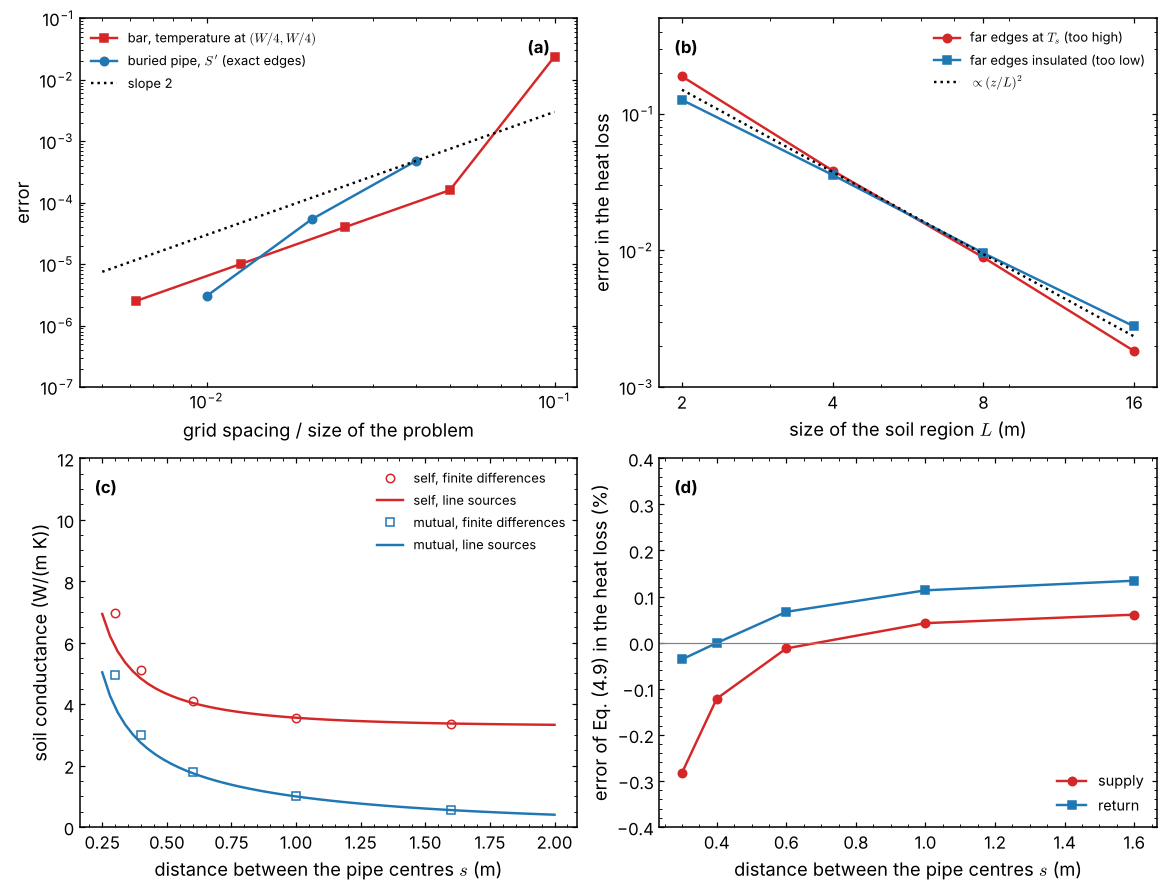

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.0))
ax = axes[0, 0]
ax.loglog(1 / (n_bar - 1), err_bar, "s-", color="C3", label="bar, temperature at $(W/4, W/4)$")
ax.loglog(hs / z, err_pipe, "o-", label="buried pipe, $S'$ (exact edges)")
hh = np.array([0.005, 0.1])
ax.loglog(hh, 0.3 * hh**2, "k:", label=r"slope 2")
ax.set_xlabel("grid spacing / size of the problem")
ax.set_ylabel("error")
ax.set_ylim(1e-7, 1e-1)
ax.legend(loc="upper left", fontsize=8.5)
panel_label(ax, "(a)", x=0.9)

ax = axes[0, 1]
ax.loglog(sizes, err_fixed, "o-", color="C3", label="far edges at $T_s$ (too high)")
ax.loglog(sizes, -err_insul, "s-", color="C0", label="far edges insulated (too low)")
ax.loglog(sizes, 0.6 * (z / sizes) ** 2, "k:", label=r"$\propto (z/L)^2$")
ax.set_xticks([2, 4, 8, 16])
ax.xaxis.set_major_formatter(plt.ScalarFormatter())
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel("size of the soil region $L$ (m)")
ax.set_ylabel("error in the heat loss")
ax.set_ylim(1e-3, 0.5)
ax.legend(loc="upper right", fontsize=8.5)
panel_label(ax, "(b)")

ax = axes[1, 0]
ax.plot(s_check, G_fd[:, 0, 0], "o", color="C3", mfc="none", label="self, finite differences")
ax.plot(spacings, [np.linalg.inv([[R_soil, two_pipes(s)[1]], [two_pipes(s)[1], R_soil]])[0, 0] for s in spacings],
        "C3", label="self, line sources")
ax.plot(s_check, -G_fd[:, 0, 1], "s", color="C0", mfc="none", label="mutual, finite differences")
ax.plot(spacings, [-np.linalg.inv([[R_soil, two_pipes(s)[1]], [two_pipes(s)[1], R_soil]])[0, 1] for s in spacings],
        "C0", label="mutual, line sources")
ax.set_xlabel("distance between the pipe centres $s$ (m)")
ax.set_ylabel("soil conductance (W/(m K))")
ax.set_ylim(0, 12)
ax.legend(loc="upper right", fontsize=8.5)
panel_label(ax, "(c)")

ax = axes[1, 1]
ax.plot(s_check, 100 * (q_line[:, 0] / q_fd[:, 0] - 1), "o-", color="C3", label="supply")
ax.plot(s_check, 100 * (q_line[:, 1] / q_fd[:, 1] - 1), "s-", color="C0", label="return")
ax.axhline(0, color="0.5", lw=0.8)
ax.set_xlabel("distance between the pipe centres $s$ (m)")
ax.set_ylabel("error of Eq. (4.9) in the heat loss (%)")
ax.set_ylim(-0.4, 0.4)
ax.legend(loc="lower right")
panel_label(ax, "(d)")
plt.show()

**Figure 4.3.** Checks. (a) Errors of the finite differences: in the bar against the
series (4.3), and in the shape factor of the buried pipe against Eq. (4.7) with the exact
temperature on the edges of the grid; the dotted line has slope 2. (b) Error in the heat
loss of the buried pipe when the soil is cut off at a distance $L$, with the far edges held
at the surface temperature or insulated. (c) Elements of the soil conductance matrix of two
casings, exact (finite differences) and from line sources, Eq. (4.9). (d) Error of the
line-source model in the heat losses of the pre-insulated supply and return pipes.

The solver converges at second order or faster: the bar to $3 \times 10^{-6}$ with 161
nodes a side, and the pipe's shape factor to $3 \times 10^{-6}$ with 10 mm cells. Cutting the soil off at a finite distance is a larger error,
falling as $(z/L)^2$: 2 % for an 8 m square with the far edges held at the surface
temperature, and of the opposite sign with them insulated. The mean of the two is within
$3 \times 10^{-4}$ of the exact answer, which is how the two-pipe checks were run.

For two bare casings close together, line sources are a poor model of the soil: at
$s = 0.3$ m the mutual conductance is 22 % too small, because the casings are not
isothermal circles of a single line source each. But for the pre-insulated pipes, the
heat losses from Eq. (4.9) agree with the exact ones to 0.3 % even there, and to 0.1 % at
the 0.4 m of the text. The foam carries 93 % of the resistance, so an error in the soil
barely reaches the answer. This is the general rule for resistances in series: improve the
model of the resistance that dominates, not of the others.

## 4.6 What to trust

* *The soil.* Its conductivity depends on its moisture and changes through the year, and
  frozen soil conducts better than unfrozen. For a pre-insulated pipe this hardly matters
  (Figure 4.2b); for a pipe whose insulation is wet or gone, it decides the loss.
* *The ground surface.* We held it at a fixed temperature. In reality it exchanges heat
  with the air, and its temperature follows the seasons; Chapter 6 treats the time
  dependence. A surface coefficient $h$ can be included by deepening the pipe by $k_s/h$
  (Exercise 2).
* *Line sources for two pipes.* Accurate for the heat losses of insulated pipes, but not
  for the temperature distribution around closely spaced bare pipes. The *multipole
  method* adds higher terms to each source to make every casing an exact isotherm; the
  finite-difference solver does the same job numerically.
* *Steady state.* The losses are annual averages if $T_s$ is the annual mean surface
  temperature, because Eq. (4.1) is linear and the seasonal swings average out.

## Summary

* Steady conduction without generation obeys Laplace's equation (4.1); its solutions are
  unique and can be superposed.
* The heat between two isothermal surfaces is $S'k\,\Delta T$ per metre, Eq. (4.2), with a
  shape factor $S'$ that depends on geometry alone.
* Separation of variables gives series like Eq. (4.3); each term decays over $W/n\pi$, so a
  disturbance on the edge of a strip of width $W$ fades within about $W$, Eq. (4.4).
* A line source and its image below an isothermal surface give the buried cylinder,
  $S' = 2\pi/\cosh^{-1}(z/r)$, Eq. (4.7).
* A buried pre-insulated pipe loses heat through the foam and the soil in series,
  Eq. (4.8); the soil adds only a few per cent. Two pipes interact through a mutual
  resistance, Eq. (4.9).

## Exercises

Sample solutions are in [`solutions/part1_conduction/04_solutions.ipynb`](../../solutions/part1_conduction/04_solutions.ipynb).

1. **A buried cable.** The 16 mm² copper cable of Chapter 2 (1.2 mm of PVC) is buried
   0.7 m deep in soil with $k_s = 1.0$ W/(m K), with the ground surface at 20 °C in summer.
   The copper may reach 70 °C. Find its ampacity and compare it with the 79 A it carries
   in air at 30 °C. What if the soil around it dries out to $k_s = 0.4$ W/(m K)?
2. **The ground surface.** Instead of a fixed surface temperature, let the surface lose
   heat to air at 0 °C with $h = 15$ W/(m² K). A common rule replaces this resistance by an
   extra layer of soil of thickness $k_s/h$, so that the pipe is effectively at depth
   $z + k_s/h$. Test the rule with `reference.laplace_2d_fd` (use `top=("convection", h,
   T_air)`) for the bare steel pipe of Section 4.3, and for the pre-insulated pipe.
3. **Wet insulation.** Water that enters the foam through a damaged joint raises its
   conductivity to about 0.15 W/(m K). How much more does a kilometre of supply pipe lose
   in a year, and how much does the soil now contribute to the resistance? How does a
   pipe with no insulation at all compare?
4. **Two hot faces.** In the bar of Section 4.2, let the bottom face and the left face both
   be at 100 °C, and the other two at 20 °C. Use superposition of two series like
   Eq. (4.3) to find the temperature at the centre and at the point (W/4, W/4), and check
   with `reference.laplace_2d_fd`.

## Suggested references

* H. S. Carslaw and J. C. Jaeger, *Conduction of Heat in Solids*, 2nd ed. (Oxford
  University Press, 1959).
* G. H. Shortley and R. Weller, "The numerical solution of Laplace's equation",
  *J. Appl. Phys.* **9**, 334 (1938).
* E. Hahne and U. Grigull, "Formfaktor und Formwiderstand der stationären
  mehrdimensionalen Wärmeleitung", *Int. J. Heat Mass Transfer* **18**, 751 (1975).
* P. Wallentén, *Steady-State Heat Loss from Insulated Pipes*, Licentiate thesis, Lund
  University (1991).
* EN 13941-1:2019+A1:2021, *District heating pipes — Design and installation of thermal
  insulated bonded single and twin pipe systems for directly buried hot water networks —
  Part 1: Design* (European Committee for Standardization, 2021).

---

**Previous:** [3. Fins and extended surfaces](03_fins.ipynb) &nbsp;·&nbsp; **Next:** [5. Transient conduction](05_transient.ipynb)